In [1]:
import sys
import os
import glob

# Get the absolute path to the parent directory
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))

# Add hybrid_lasso to sys.path
sys.path.append(project_root)

# Now, import should work
from hybrid_lasso.model_ar_reg import AdaptiveRidgeRegression

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

from lassonet import LassoNetRegressor
import seaborn as sns
import torch

In [4]:
def plot_nimo(ckpt, train_df, figsize1=(4, 3), figsize2=(1, 6), hidden_dim=None, name=None):
    if hidden_dim is None:
        model = AdaptiveRidgeRegression.load_from_checkpoint(ckpt)
    else:
        model = AdaptiveRidgeRegression.load_from_checkpoint(ckpt, hidden_dim=hidden_dim)

    beta = model.beta.detach().cpu().numpy()
    beta_0 = model.beta_0.detach().cpu().numpy()

    print(beta, beta_0)

    plt.figure(figsize=figsize1)
    plt.gca().set_axisbelow(True)

    feature_names = train_df.columns[:-1].tolist() + ["Intercept"]
    coefficients = np.append(beta, beta_0)
    plt.barh(feature_names, coefficients)
    plt.xlabel("Coefficient Value")
    plt.ylabel("Feature Name")
    plt.title("Feature Coefficients of NIMO")
    if name is not None:
        plt.savefig(f"../{name}_nimo_coeff.pdf", dpi=300)
    plt.show()

    # Plot FC layer weights
    first_fc_layer = model.fc1.weight.detach().cpu().numpy()
    first_fc_layer = first_fc_layer[:, : len(train_df.columns) - 1]

    plt.figure(figsize=figsize2)
    plt.imshow(first_fc_layer, aspect="auto", cmap="viridis", vmin=-1, vmax=1)
    plt.colorbar(label="Weight Magnitude")
    plt.title("First FC Layer Weights")
    if first_fc_layer.shape[1] <= 5:
        plt.xticks(ticks=[0, first_fc_layer.shape[1] - 1], labels=[1, first_fc_layer.shape[1]])
    else:
        plt.xticks(
            ticks=np.arange(0, first_fc_layer.shape[1], 5),
            labels=np.arange(1, first_fc_layer.shape[1] + 1, 5),
        )
    plt.xlabel("Input Features")
    plt.ylabel("Neurons")
    if name is not None:
        plt.savefig(f"../{name}_fc_weights.pdf", dpi=300)
    plt.show()

    return coefficients

### Diabetes

In [66]:
train_df = pd.read_csv("../data/diabetes_9/train.csv")
val_df = pd.read_csv("../data/diabetes_9/val.csv")
test_df = pd.read_csv("../data/diabetes_9/test.csv")

X_train = train_df.drop(columns=["target"]).values
y_train = train_df["target"].values.astype(float)
X_val = val_df.drop(columns=["target"]).values
y_val = val_df["target"].values.astype(float)
X_test = test_df.drop(columns=["target"]).values
y_test = test_df["target"].values.astype(float)

In [69]:
feat_names_d = train_df.columns[:-1].tolist()
feat_names_d

['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

In [53]:
X_train.shape, y_train.shape, X_val.shape, y_val.shape, X_test.shape, y_test.shape

((264, 10), (264,), (89, 10), (89,), (89, 10), (89,))

==> training with noise_injection=False
AdaptiveRidgeRegression(
  (fc1): Linear(in_features=14, out_features=64, bias=True)
  (fc2): Linear(in_features=68, out_features=128, bias=True)
  (fc3): Linear(in_features=196, out_features=1, bias=True)
  (dropout2): Identity()
)
==> training with noise_injection=False
[ 2.5649318e-02 -6.8989225e-02  3.0435494e-01  1.7933945e-01
 -8.5539520e-03 -0.0000000e+00 -1.6235763e-01  1.0222764e-08
  2.3548205e-01  7.2390050e-02] [0.]


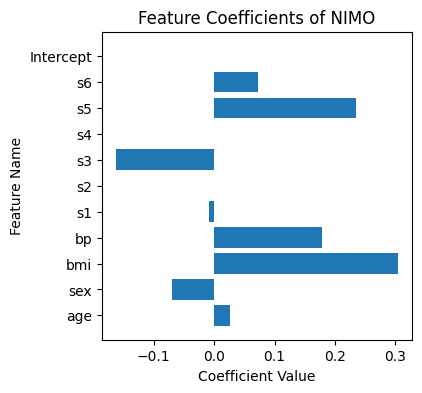

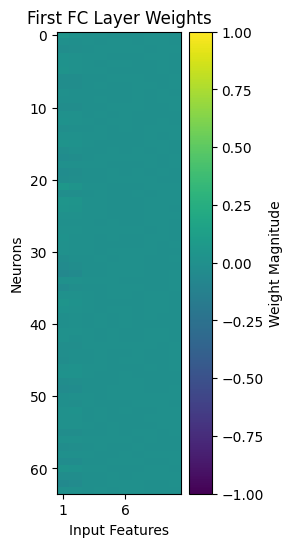

In [54]:
# split = 9
# penalty = 1.0

split = 8
penalty = 0.5
ckpt_dir = f"../tb_logs/ar_reg_diabetes_{split}_lp_{penalty}/version_0/checkpoints/"
ckpt_files = glob.glob(os.path.join(ckpt_dir, "*.ckpt"))
model_ckpt = ckpt_files[0]

model = AdaptiveRidgeRegression.load_from_checkpoint(model_ckpt)
print(model)

nimo_coeff = plot_nimo(model_ckpt, train_df, figsize1=(4, 4), figsize2=(2, 6))

In [55]:
beta = model.beta.detach().cpu().numpy()
beta_0 = model.beta_0.detach().cpu().numpy()

model.eval()
with torch.no_grad():
    B_u = model.build_B_u(torch.tensor(X_test, dtype=torch.float32).to("cuda"))
    G_u = model.compute_nonlinearity(torch.tensor(X_test, dtype=torch.float32).to("cuda"))


# convert B_u and G_u to numpy
B_u = B_u.cpu().numpy()
G_u = G_u.cpu().numpy()
print(beta, beta_0)
print(B_u.shape)

[ 2.5649318e-02 -6.8989225e-02  3.0435494e-01  1.7933945e-01
 -8.5539520e-03 -0.0000000e+00 -1.6235763e-01  1.0222764e-08
  2.3548205e-01  7.2390050e-02] [0.]
(89, 10)


In [56]:
# compute mean and std of abs(G_u) across test samples for each feature
mean_abs_G_u_d = np.mean(np.abs(G_u), axis=0)
std_abs_G_u_d = np.std(np.abs(G_u), axis=0)

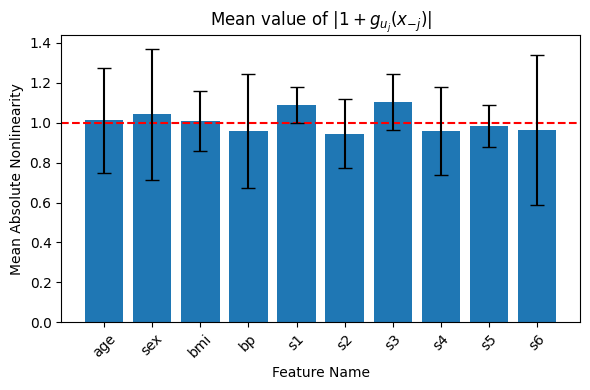

In [58]:
# plot bar plot of mean_abs_G_u with error bars as std_abs_G_u

feature_names = train_df.columns[:-1].tolist()
plt.figure(figsize=(6, 4))
plt.axhline(y=1, linestyle="--", color="red")  # <-- add y=1 line
plt.bar(feature_names, mean_abs_G_u_d, yerr=std_abs_G_u_d, capsize=5)
plt.xlabel("Feature Name")
plt.ylabel("Mean Absolute Nonlinearity")
plt.title("Mean value of $|1+ g_{u_j}(x_{-j})|$")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Boston

In [70]:
train_df = pd.read_csv("../data/boston_2/train.csv")
val_df = pd.read_csv("../data/boston_2/val.csv")
test_df = pd.read_csv("../data/boston_2/test.csv")

X_train = train_df.drop(columns=["target"]).values
y_train = train_df["target"].values.astype(float)
X_val = val_df.drop(columns=["target"]).values
y_val = val_df["target"].values.astype(float)
X_test = test_df.drop(columns=["target"]).values
y_test = test_df["target"].values.astype(float)

In [71]:
feat_names_b = train_df.columns[:-1].tolist()
feat_names_b

['CRIM',
 'ZN',
 'INDUS',
 'CHAS',
 'NOX',
 'RM',
 'AGE',
 'DIS',
 'RAD',
 'TAX',
 'PTRATIO',
 'B',
 'LSTAT']

==> training with noise_injection=False
AdaptiveRidgeRegression(
  (fc1): Linear(in_features=17, out_features=64, bias=True)
  (fc2): Linear(in_features=68, out_features=128, bias=True)
  (fc3): Linear(in_features=196, out_features=1, bias=True)
  (dropout2): Identity()
)
==> training with noise_injection=False
[-0.03237752  0.00914199 -0.05200826  0.07115339 -0.          0.285845
 -0.07274994 -0.2768911   0.28749105 -0.0766243  -0.11038455  0.04337269
 -0.1887033 ] [0.]


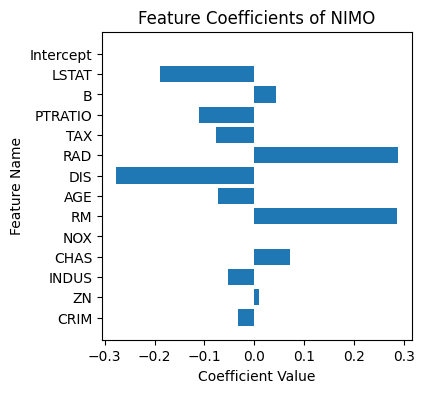

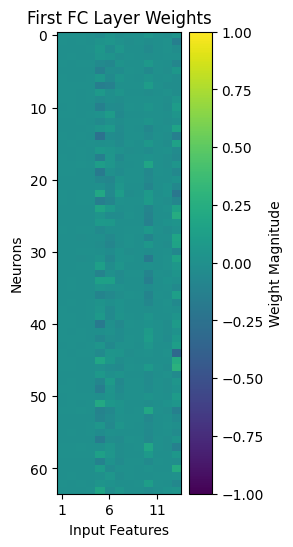

In [60]:
ckpt_dir = f"../tb_logs/ar_reg_boston_2_lp_0.15/version_0/checkpoints/"
ckpt_files = glob.glob(os.path.join(ckpt_dir, "*.ckpt"))
model_ckpt = ckpt_files[0]

model = AdaptiveRidgeRegression.load_from_checkpoint(model_ckpt)
print(model)

nimo_coeff = plot_nimo(model_ckpt, train_df, figsize1=(4, 4), figsize2=(2, 6))

In [61]:
beta = model.beta.detach().cpu().numpy()
beta_0 = model.beta_0.detach().cpu().numpy()

model.eval()
with torch.no_grad():
    B_u = model.build_B_u(torch.tensor(X_test, dtype=torch.float32).to("cuda"))
    G_u = model.compute_nonlinearity(torch.tensor(X_test, dtype=torch.float32).to("cuda"))


# convert B_u and G_u to numpy
B_u = B_u.cpu().numpy()
G_u = G_u.cpu().numpy()
print(beta, beta_0)
print(B_u.shape)

[-0.03237752  0.00914199 -0.05200826  0.07115339 -0.          0.285845
 -0.07274994 -0.2768911   0.28749105 -0.0766243  -0.11038455  0.04337269
 -0.1887033 ] [0.]
(102, 13)


In [63]:
# compute mean and std of abs(G_u) across test samples for each feature
mean_abs_G_u_b = np.mean(np.abs(G_u), axis=0)
std_abs_G_u_b = np.std(np.abs(G_u), axis=0)

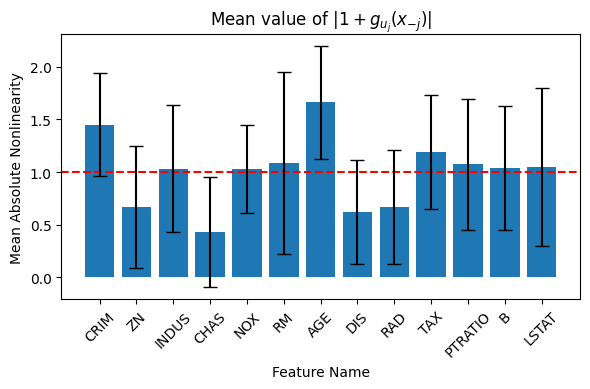

In [64]:
# plot bar plot of mean_abs_G_u with error bars as std_abs_G_u

feature_names = train_df.columns[:-1].tolist()
plt.figure(figsize=(6, 4))
plt.axhline(y=1, linestyle="--", color="red")  # <-- add y=1 line
plt.bar(feature_names, mean_abs_G_u_b, yerr=std_abs_G_u_b, capsize=5)
plt.xlabel("Feature Name")
plt.ylabel("Mean Absolute Nonlinearity")
plt.title("Mean value of $|1+ g_{u_j}(x_{-j})|$")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

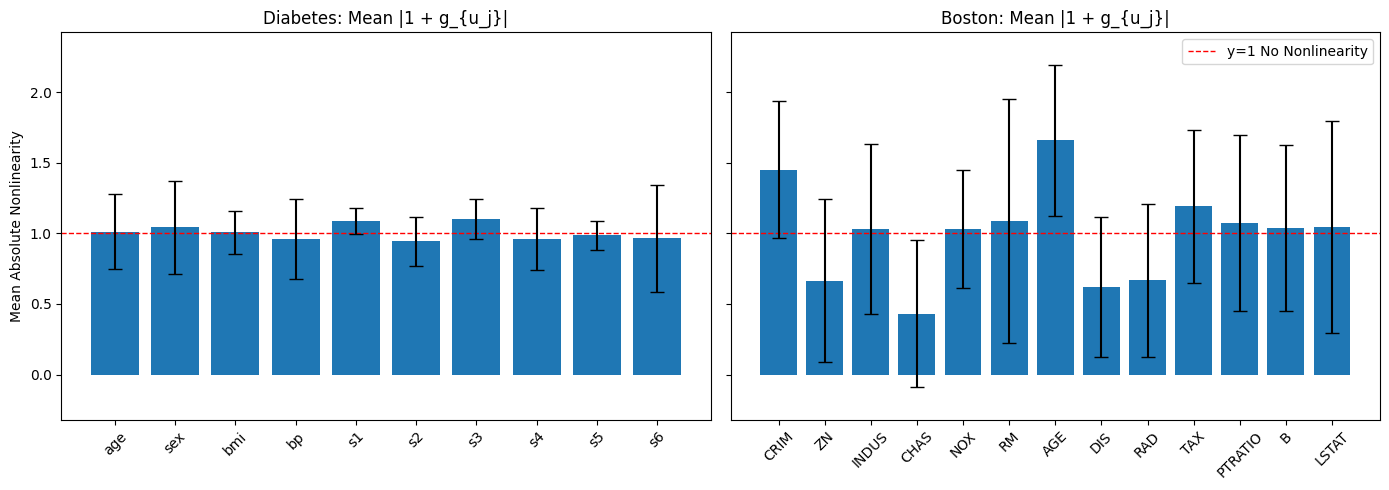

: 

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# compute common y-limits from means +/- stds
ymin = min((mean_abs_G_u_d - std_abs_G_u_d).min(), (mean_abs_G_u_b - std_abs_G_u_b).min())
ymax = max((mean_abs_G_u_d + std_abs_G_u_d).max(), (mean_abs_G_u_b + std_abs_G_u_b).max())
pad = 0.1 * (ymax - ymin) if (ymax - ymin) != 0 else 0.1
ylim = (ymin - pad, ymax + pad)

# Diabetes (left)
axes[0].axhline(1, linestyle="--", color="red", linewidth=1)
axes[0].bar(range(len(mean_abs_G_u_d)), mean_abs_G_u_d, yerr=std_abs_G_u_d, capsize=5)
axes[0].set_xticks(range(len(feat_names_d)))
axes[0].set_xticklabels(feat_names_d, rotation=45)
axes[0].set_title("Diabetes: Mean |1 + g_{u_j}|")
axes[0].set_ylabel("Mean Absolute Nonlinearity")
axes[0].set_ylim(ylim)

# Boston (right)
axes[1].axhline(1, linestyle="--", color="red", linewidth=1)
axes[1].bar(range(len(mean_abs_G_u_b)), mean_abs_G_u_b, yerr=std_abs_G_u_b, capsize=5)
axes[1].set_xticks(range(len(feat_names_b)))
axes[1].set_xticklabels(feat_names_b, rotation=45)
axes[1].set_title("Boston: Mean |1 + g_{u_j}|")
axes[1].set_ylim(ylim)

plt.legend(["y=1 No Nonlinearity"], loc="upper right")
plt.tight_layout()
plt.savefig("../degree_of_nonlin.pdf", dpi=300)
plt.show()